# EDA исходных датасетов (до обогащения)

**Курсовая работа:** «Сравнительный анализ влияния ручного и искусственного обогащения данных на качество и устойчивость обучения моделей машинного обучения».

**Этап 1 (21.10.26):** выбор датасетов, журнал работы, предварительный список источников реальных данных, начало анализа исходных датасетов.

| | Датасет 1 — текст | Датасет 2 — изображения |
|---|---|---|
| Название | RuSentiTweet | TrashNet |
| Задача | классификация тональности, 5 классов | классификация изображений, 6 классов |
| Объём | 13 392 твита | 2 527 фото |
| Источник | github.com/sismetanin/rusentitweet | github.com/garythung/trashnet |
| Лицензия | открытый датасет к статье в PeerJ CS (2022), цитирование обязательно | MIT |

Все метрики считаются функциями из `src/`, сводки сохраняются в `reports/eda_before/*.json` — после обогащения тот же код запускается на новых данных, и сводки сравниваются.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from src import download, eda_text as T, eda_images as I

OUT = ROOT / "reports" / "eda_before"
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")

In [2]:
# Скачивает данные в data/raw, если их ещё нет (пропускает уже скачанное)
download.download_rusentitweet()
download.download_trashnet();

[skip] data/raw/rusentitweet/rusentitweet_full.csv уже есть
[skip] data/raw/rusentitweet/rusentitweet_train.csv уже есть
[skip] data/raw/rusentitweet/rusentitweet_test.csv уже есть
[skip] data/raw/trashnet/dataset-resized.zip уже есть
[skip] data/raw/trashnet/one-indexed-files-notrash_train.txt уже есть
[skip] data/raw/trashnet/one-indexed-files-notrash_val.txt уже есть
[skip] data/raw/trashnet/one-indexed-files-notrash_test.txt уже есть


## 1. RuSentiTweet

Твиты на русском из архива Twitter Stream Grab, размечены краудсорсингом по инструкции RuSentiment (фактически — готовый codebook). Классы:

- `positive` / `negative` / `neutral` — тональность автора;
- `speech` — речевой акт: благодарность, поздравление, приветствие;
- `skip` — нерелевантное: шум, другой язык, непонятный текст.

По данным авторов (ноутбук «Labels Aggregation» в репозитории), согласие разметчиков — Krippendorff $\alpha \approx 0{,}505$ для номинальной шкалы, то есть умеренное. Это важно для курсовой: исходные метки сами по себе зашумлены, и шум разметки нужно учитывать при оценке эффекта обогащения.

In [3]:
full = pd.read_csv(ROOT / "data/raw/rusentitweet/rusentitweet_full.csv", index_col=0)
train = pd.read_csv(ROOT / "data/raw/rusentitweet/rusentitweet_train.csv")
test = pd.read_csv(ROOT / "data/raw/rusentitweet/rusentitweet_test.csv")
print("full:", full.shape, " train:", train.shape, " test:", test.shape)
print("Пересечение id train/test:", len(set(train.id) & set(test.id)))
print("Пропуски:\n", full.isna().sum().to_string())
full.sample(8, random_state=0)

full: (13392, 3)  train: (10713, 3)  test: (2679, 3)
Пересечение id train/test: 0
Пропуски:
 text     0
label    0
id       0


,text,label,id
1586,@UrgvRazvedka Что? Мы накануне большого шухера???🙊,negative,1295781327824920577
1453,"сижу, читаю аушки хёна и просто:\r\n-Я КТО НАХЕР",negative,1212385641629179904
11411,@GoodOldEkans нет,neutral,1327694952294440962
7289,"@_Kipyatok А то получается, что черный вертолет как пятно на розовом фоне и забирает всю информацию с картинки в общ...",negative,1307973959837777921
9969,Коронавирус не подтвердился у госпитализированных воронежцев,neutral,1222789063268360192
2604,"ладно, признаю, шутка не очень",neutral,1237417440876941312
6673,@typoe09 ХХЖАЖЦЖЙДЙЬЙБЙЬ,skip,1281532098524983298
10979,@Happy_Sunshinee @oopsyyyyyyyy Иха,skip,1337482016732884994


### 1.1. Распределение классов

,count,share,train,test
label,,,,
positive,2414,0.1803,0.1802,0.1803
neutral,5341,0.3988,0.3989,0.3987
negative,3298,0.2463,0.2462,0.2464
speech,496,0.0370,0.0371,0.0370
skip,1843,0.1376,0.1376,0.1377


Дисбаланс max/min: 10.77


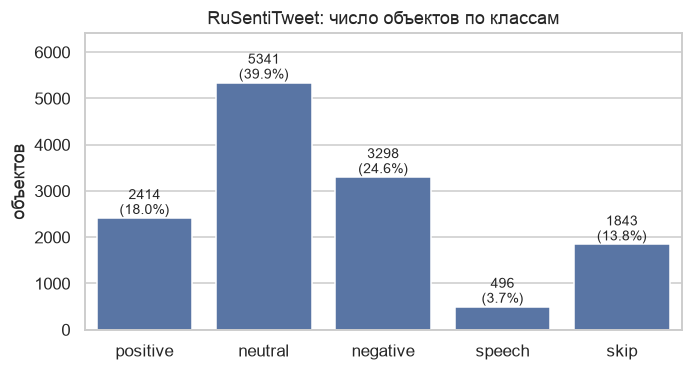

In [4]:
dist = T.class_distribution(full)
split = pd.concat({
    "train": train["label"].value_counts(normalize=True),
    "test": test["label"].value_counts(normalize=True),
}, axis=1).reindex(dist.index).round(4)
display(dist.join(split))
print("Дисбаланс max/min:", round(T.imbalance_ratio(full), 2))

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=dist.index, y=dist["count"], ax=ax, color="#4C72B0")
for i, v in enumerate(dist["count"]):
    ax.text(i, v, f"{v}\n({dist['share'].iloc[i]:.1%})", ha="center", va="bottom", fontsize=9)
ax.set(title="RuSentiTweet: число объектов по классам", xlabel="", ylabel="объектов")
ax.set_ylim(0, dist["count"].max() * 1.2)
save(fig, "text_class_distribution")

Классы сильно несбалансированы: `neutral` почти 40 %, `speech` — меньше 4 % (дисбаланс $\approx 10{,}8$ раза). Разбиение train/test стратифицировано — доли совпадают, утечки по `id` нет. Значит, главная цель обогащения для текстов — **малые классы `speech` и `positive`**, и метрикой качества дальше должна быть macro-F1, а не accuracy.

### 1.2. Длина текстов и особенности твитов

,n_chars,n_words,has_url,has_mention,has_hashtag,has_emoji
label,,,,,,
positive,51.0,6.0,0.196,0.606,0.022,0.340
neutral,52.0,6.0,0.271,0.588,0.027,0.106
negative,62.0,8.0,0.134,0.522,0.015,0.115
speech,35.0,2.0,0.153,0.839,0.020,0.550
skip,43.0,4.0,0.199,0.672,0.019,0.184


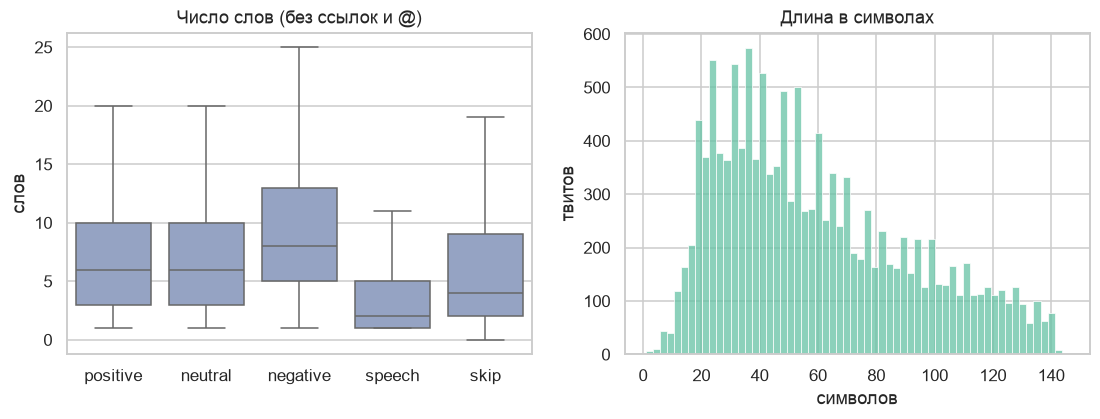

In [5]:
F = T.add_features(full)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.boxplot(data=F, x="label", y="n_words", order=dist.index, ax=axes[0], showfliers=False, color="#8DA0CB")
axes[0].set(title="Число слов (без ссылок и @)", xlabel="", ylabel="слов")
sns.histplot(F["n_chars"], bins=60, ax=axes[1], color="#66C2A5")
axes[1].set(title="Длина в символах", xlabel="символов", ylabel="твитов")
save(fig, "text_lengths")

feat = F.groupby("label")[["n_chars", "n_words"]].median().join(
    F.groupby("label")[["has_url", "has_mention", "has_hashtag"]].mean().round(3)
).join((F.groupby("label")["n_emoji"].apply(lambda s: (s > 0).mean())).rename("has_emoji").round(3)).reindex(dist.index)
feat

Тексты короткие — медиана 6 слов. Около 60 % твитов содержат упоминания `@user`, около 20 % — ссылки: это шум, который нужно чистить или заменять токенами. Эмодзи встречаются в ~18 % твитов и заметно связаны с тональностью — их стоит оставить как признак. Распределение обрывается около 140 символов — это старый лимит Twitter, твиты собраны до его повышения.

### 1.3. Язык и класс `skip`

Твитов с долей кириллицы < 0.5: 21


,text,label
2326,@maybentt смотря сколько у тебя времени,skip
3751,@ganbaatar_prv @Ragchaadalai хоолойны өвчинд сайн гэдэг хүмүүс идэж л бсн,skip
1815,@jlmh_mngl Тм юм бн лээ онцгой гэсэн нэр орчихоор л нэг газар болчихгүй,skip
10531,"@OcLhS3R368VBd36 @7tfp9VMKVSAl7XE @kqwetto1 @Wraith97963213 @Staywithfun А бля, это рофло акк, забайтил",skip
2099,@femislesh аче реклама,skip
9308,@vikalee @atomic_bomb_80 Конечно. За 7 лет сколько людей заразила? 🤣,skip
11065,СТОЛЬКО ЛЮДЕЙ ЗА,skip
12695,Ночи\r\nЧпуньк,skip


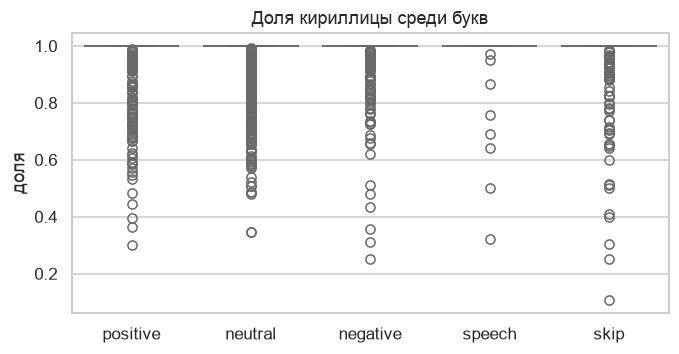

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.3))
sns.boxplot(data=F, x="label", y="cyr_share", order=dist.index, ax=ax, color="#FC8D62")
ax.set(title="Доля кириллицы среди букв", xlabel="", ylabel="доля")
save(fig, "text_cyrillic_share")
print("Твитов с долей кириллицы < 0.5:", int((F["cyr_share"] < 0.5).sum()))
F[F["label"] == "skip"].sample(8, random_state=1)[["text", "label"]]

В `skip` попадают твиты на других языках, прежде всего монгольском (кириллица, но слова «байна», «гэж», «дээ»), и бессодержательные ответы. Для обогащения это значит: реальные данные, собранные вручную, придётся фильтровать по языку, иначе они раздуют `skip`.

### 1.4. Частотные слова по классам

In [7]:
tops = {lab: [w for w, _ in T.top_tokens(full, lab, 12)] for lab in dist.index}
pd.DataFrame(tops)

,positive,neutral,negative,speech,skip
0,люблю,почему,блять,спасибо,хочу
1,очень,ещё,пиздец,доброе,блять
2,хочу,хочу,вообще,утро,байна
3,всё,всё,ещё,большое,вообще
4,спасибо,знаю,всё,поздравляю,гэж
5,нравится,вообще,почему,привет,дээ
6,тебе,тебе,хочу,ночи,тебе
7,ещё,понимаю,нахуй,всем,ещё
8,буду,сегодня,очень,рождения,всё
9,вау,фото,бля,тебе,знаю


Лексика классов ожидаемая: `speech` — «спасибо», «поздравляю», «доброе утро»; `negative` — в основном обсценная лексика. Это значит, что модель легко научится на ключевых словах, а обогащение должно добавлять примеры **без** очевидных маркеров (негатив без мата, позитив без «люблю»), чтобы проверять устойчивость.

### 1.5. Дубликаты и противоречивые метки

In [8]:
dups = T.duplicates_report(full)
print(json.dumps(dups, ensure_ascii=False, indent=1))

norm = full["text"].map(T.clean_for_tokens).str.replace(r"\s+", " ", regex=True).str.strip()
g = full.assign(norm=norm).groupby("norm")["label"].agg(["nunique", "count", lambda s: ", ".join(sorted(set(s)))])
g.columns = ["n_labels", "n_rows", "labels"]
g[g["n_labels"] > 1].sort_values("n_rows", ascending=False).head(10)

{
 "exact_dup_rows": 0,
 "normalized_dup_rows": 328,
 "dup_groups_with_conflicting_labels": 38
}


,n_labels,n_rows,labels
norm,,,
да,2,31,"neutral, skip"
нет,2,11,"neutral, skip"
что,2,8,"neutral, skip"
спасибо!,2,7,"positive, speech"
#tales of wind# отправляйтесь в путешествие и спешите навстречу приключениям вместе с друзьями!,2,5,"neutral, positive"
да!,2,5,"neutral, skip"
согласна,2,5,"neutral, positive"
ору,3,5,"neutral, positive, skip"
хорошо,2,4,"neutral, positive"


Точных дублей нет, но после удаления ссылок и упоминаний 328 строк совпадают, и в 38 группах одинаковый текст имеет **разные метки**. Это прямое подтверждение шума разметки ($\alpha \approx 0{,}5$). При ручной доразметке эти случаи — готовый материал для раздела codebook «спорные примеры».

In [9]:
text_summary = T.summary(full, "rusentitweet_full")
(OUT / "text_summary.json").write_text(json.dumps(text_summary, ensure_ascii=False, indent=2))
text_summary

{'dataset': 'rusentitweet_full',
 'n_rows': 13392,
 'n_classes': 5,
 'class_counts': {'neutral': 5341,
  'negative': 3298,
  'positive': 2414,
  'skip': 1843,
  'speech': 496},
 'imbalance_ratio_max_min': 10.77,
 'chars_median': 52.0,
 'words_median': 6.0,
 'share_with_url': 0.2095,
 'share_with_mention': 0.596,
 'share_with_emoji': 0.1775,
 'share_empty_after_clean': 0.0004,
 'vocab_size': 26136,
 'exact_dup_rows': 0,
 'normalized_dup_rows': 328,
 'dup_groups_with_conflicting_labels': 38}

## 2. TrashNet

Фотографии бытовых отходов на белом фоне, сделанные авторами вручную (Stanford, 2017), 6 классов: `cardboard`, `glass`, `metal`, `paper`, `plastic`, `trash`. В репозитории — версия, уменьшенная до 512×384, и списки разбиения train/val/test.

Датасет хорошо подходит под тему курсовой: съёмка однородная (один фон, одно освещение), поэтому можно прямо проверить, улучшает ли обогащение **устойчивость к смене домена** — реальными фото в других условиях (ручное обогащение) или аугментациями и генерацией (искусственное).

In [10]:
IMG_ROOT = ROOT / "data/raw/trashnet/dataset-resized"
img = I.scan(IMG_ROOT)
print(img.shape, "| битых файлов:", int(img["corrupted"].sum()))
img.head()

(2527, 17) | битых файлов: 0


,path,file,label,bytes,width,height,mode,mean_r,mean_g,mean_b,brightness,contrast,colorfulness,phash,md5,corrupted,aspect
0,/Users/delusionn/prog/kursovaya 2/data/raw/trashnet/dataset-resized/cardboard/cardboard1.jpg,cardboard1.jpg,cardboard,17333,512,384,RGB,0.741195,0.609811,0.496925,0.615977,0.159171,0.244270,d5aa2f5490ffba00,336f2740cc7c60ac7544ad47e34dc602,False,1.333333
1,/Users/delusionn/prog/kursovaya 2/data/raw/trashnet/dataset-resized/cardboard/cardboard10.jpg,cardboard10.jpg,cardboard,21683,512,384,RGB,0.729663,0.640392,0.558853,0.642969,0.166946,0.171692,e626655919daa726,b37669c0dcf8eb3939bb35c7be9796fb,False,1.333333
2,/Users/delusionn/prog/kursovaya 2/data/raw/trashnet/dataset-resized/cardboard/cardboard100.jpg,cardboard100.jpg,cardboard,14884,512,384,RGB,0.729796,0.711460,0.692346,0.711201,0.180817,0.051157,f1cf2518e4b2994e,fb79c3308ad68dbac1cf23c244fc0fa5,False,1.333333
3,/Users/delusionn/prog/kursovaya 2/data/raw/trashnet/dataset-resized/cardboard/cardboard101.jpg,cardboard101.jpg,cardboard,14289,512,384,RGB,0.583150,0.499124,0.403800,0.495358,0.283388,0.179350,b3646d99c9538867,733b19b0875874a4804dc2b3bf7a2c08,False,1.333333
4,/Users/delusionn/prog/kursovaya 2/data/raw/trashnet/dataset-resized/cardboard/cardboard102.jpg,cardboard102.jpg,cardboard,18015,512,384,RGB,0.678547,0.641975,0.597578,0.639367,0.189761,0.085578,c2c92fc23e69966c,eded15aa90832e6144fccb292448ef43,False,1.333333


### 2.1. Распределение классов и разбиение

,count,share,train,val,test
label,,,,,
cardboard,403,0.1595,287,46,70
glass,501,0.1983,354,65,82
metal,410,0.1622,286,56,68
paper,594,0.2351,403,83,108
plastic,482,0.1907,347,61,74
trash,137,0.0542,91,17,29


Дисбаланс max/min: 4.34


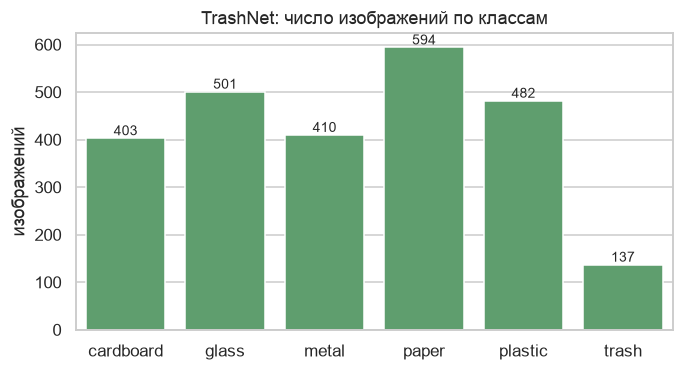

In [11]:
idist = I.class_distribution(img)
splits = {}
for part in ["train", "val", "test"]:
    lines = (ROOT / f"data/raw/trashnet/one-indexed-files-notrash_{part}.txt").read_text().split()
    names = lines[0::2]
    splits[part] = pd.Series(names).str.replace(r"\d+\.jpg$", "", regex=True).value_counts()
sp = pd.DataFrame(splits).reindex(idist.index).fillna(0).astype(int)
display(idist.join(sp))
print("Дисбаланс max/min:", round(idist["count"].max() / idist["count"].min(), 2))

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=idist.index, y=idist["count"], ax=ax, color="#55A868")
for i, v in enumerate(idist["count"]):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax.set(title="TrashNet: число изображений по классам", xlabel="", ylabel="изображений")
save(fig, "img_class_distribution")

Дисбаланс умеренный ($\approx 4{,}3$ раза), самый маленький класс — `trash` (137 фото, 5,4 %). Авторское разбиение примерно 70/13/17 и стратифицировано; его можно взять как есть для воспроизводимости, но дубликаты (раздел 2.4) нужно убрать до разбиения, иначе одно и то же фото может попасть и в train, и в test. Дополнительно понадобится отдельный тест из реальных фото «в другом домене».

### 2.2. Примеры

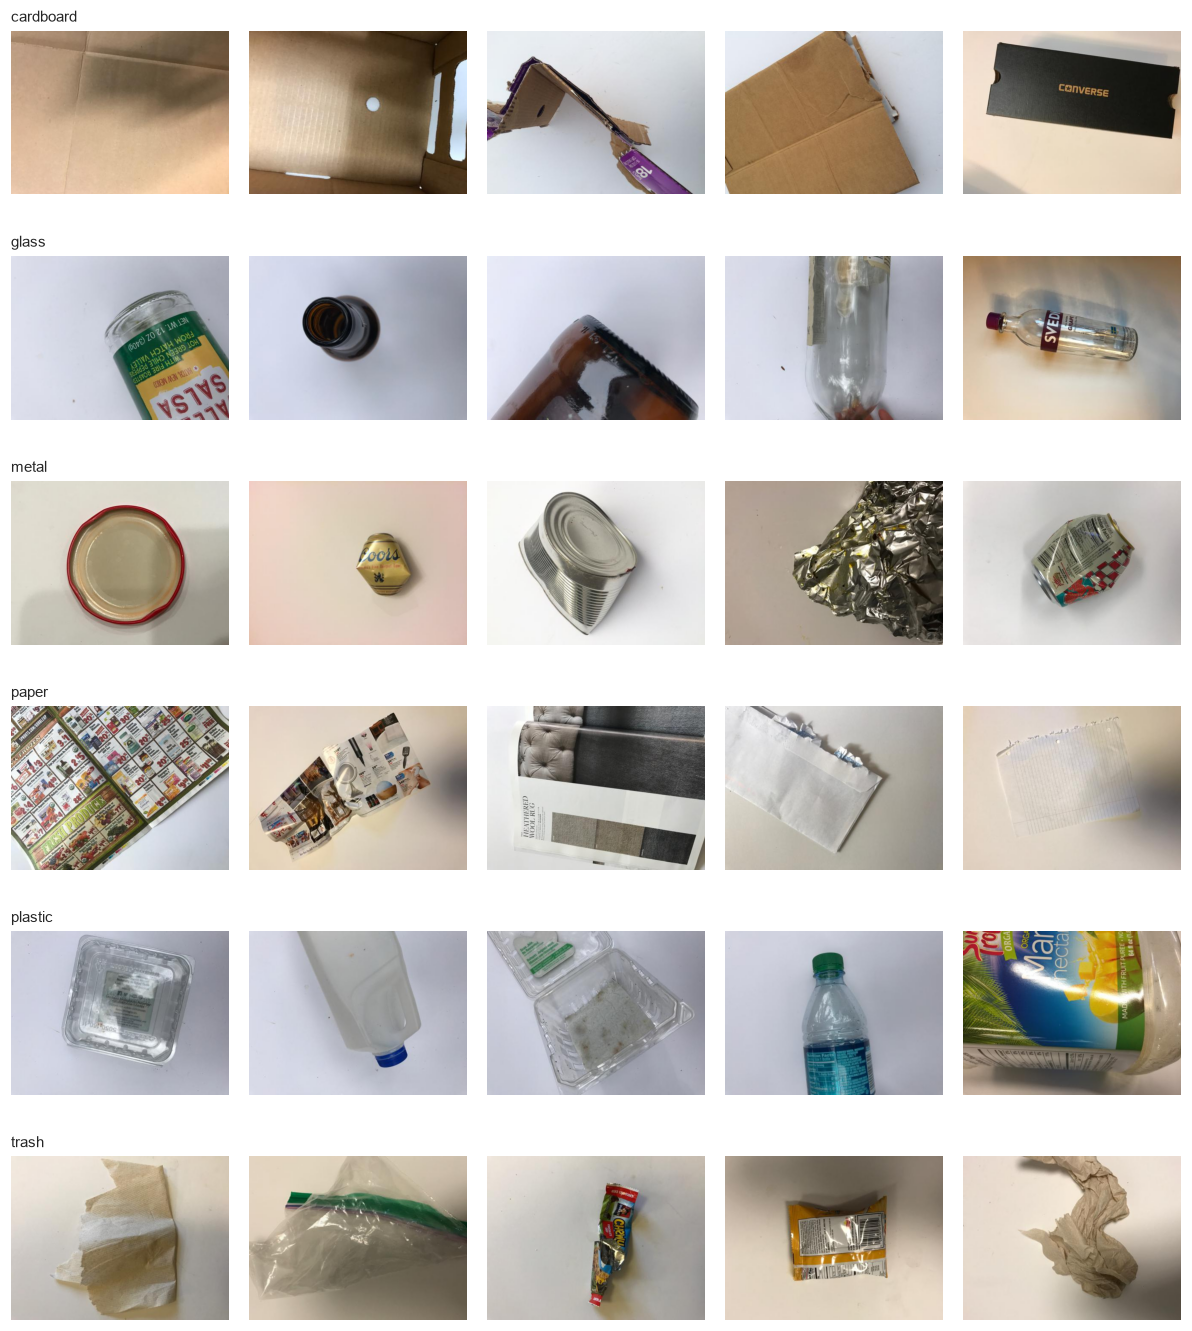

In [12]:
rng = np.random.default_rng(0)
classes = list(idist.index)
fig, axes = plt.subplots(len(classes), 5, figsize=(11, 2.1 * len(classes)))
for r, c in enumerate(classes):
    paths = img[img.label == c]["path"].to_numpy()
    for k, p in enumerate(rng.choice(paths, 5, replace=False)):
        axes[r, k].imshow(Image.open(p)); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=10)
plt.tight_layout()
save(fig, "img_examples")

### 2.3. Размеры, яркость, цвет

Разрешения: {(512, 384): 2527}
Режимы: {'RGB': 2527}


,brightness,contrast,colorfulness,bytes
label,,,,
cardboard,0.578,0.201,0.202,18918.0
glass,0.675,0.189,0.087,12745.0
metal,0.628,0.224,0.088,16572.5
paper,0.660,0.205,0.083,18330.5
plastic,0.680,0.153,0.064,13884.5
trash,0.661,0.187,0.120,13382.0


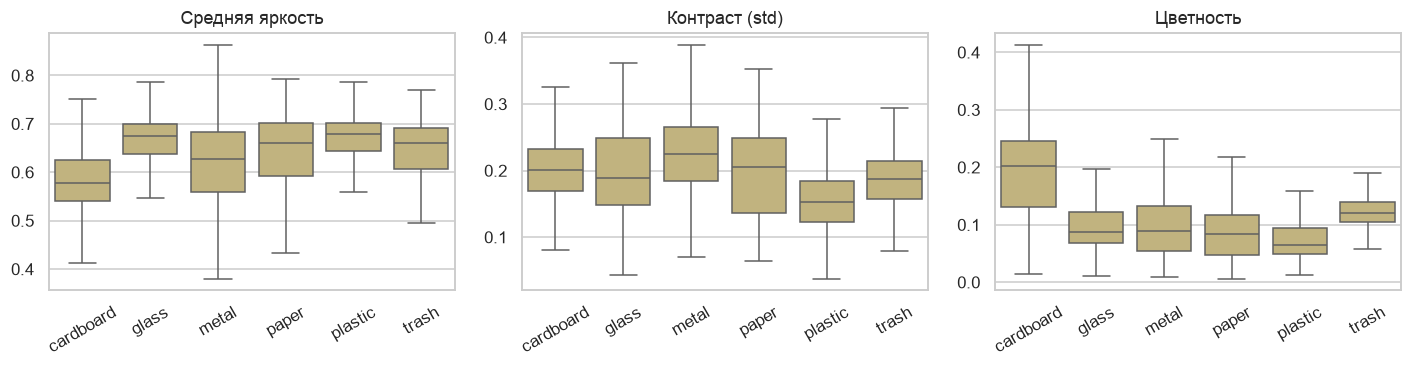

In [13]:
print("Разрешения:", img[["width", "height"]].value_counts().to_dict())
print("Режимы:", img["mode"].value_counts().to_dict())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title in zip(axes, ["brightness", "contrast", "colorfulness"],
                          ["Средняя яркость", "Контраст (std)", "Цветность"]):
    sns.boxplot(data=img, x="label", y=col, ax=ax, color="#CCB974", showfliers=False)
    ax.set(title=title, xlabel="", ylabel=""); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
save(fig, "img_color_stats")
img.groupby("label")[["brightness", "contrast", "colorfulness", "bytes"]].median().round(3)

Все изображения одного разрешения 512×384 и в RGB — предобработка размеров не нужна. Яркость высокая и почти одинаковая по классам (белый фон), цветность низкая. Это и есть главный риск: модель может опираться на условия съёмки, а не на материал. Реальные фото с цветным фоном и другим освещением должны дать заметное падение качества — его и будем «лечить» обогащением.

### 2.4. Дубликаты, в том числе между классами

In [14]:
nd = I.near_duplicates(img, max_dist=4)
print("Точных дублей (md5), строк:", int(img["md5"].duplicated(keep=False).sum()))
print("Пар почти одинаковых (pHash, расстояние ≤ 4):", len(nd))
cross = nd[nd.label_a != nd.label_b]
print("Из них в разных классах:", len(cross))
cross

Точных дублей (md5), строк: 6
Пар почти одинаковых (pHash, расстояние ≤ 4): 28
Из них в разных классах: 5


,a,label_a,b,label_b,dist
2,glass115.jpg,glass,metal91.jpg,metal,0
3,glass176.jpg,glass,plastic152.jpg,plastic,0
4,glass389.jpg,glass,plastic332.jpg,plastic,0
6,metal154.jpg,metal,plastic10.jpg,plastic,4
8,metal159.jpg,metal,plastic11.jpg,plastic,2


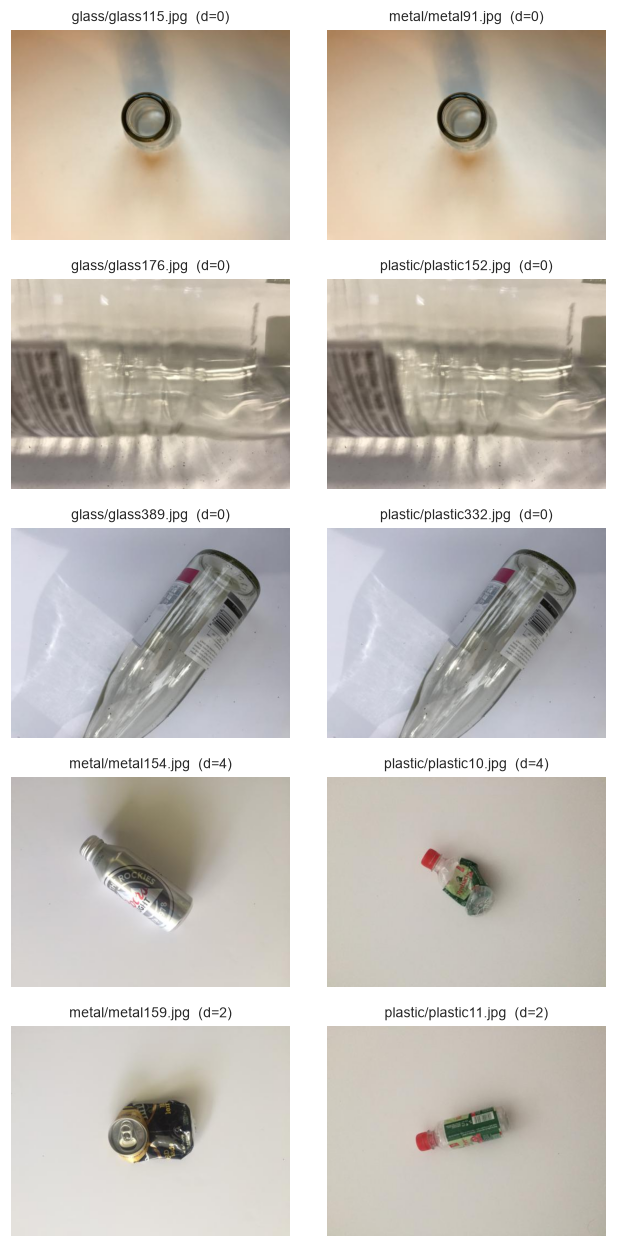

In [15]:
show = cross.head(5)
if len(show):
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 2.3 * len(show)))
    axes = np.atleast_2d(axes)
    for i, (_, r) in enumerate(show.iterrows()):
        for j, (f, l) in enumerate([(r.a, r.label_a), (r.b, r.label_b)]):
            axes[i, j].imshow(Image.open(IMG_ROOT / l / f)); axes[i, j].axis("off")
            axes[i, j].set_title(f"{l}/{f}  (d={r.dist})", fontsize=9)
    plt.tight_layout()
    save(fig, "img_cross_class_duplicates")

Пары с расстоянием 0 — это **одно и то же фото, лежащее в двух классах**: `glass115` = `metal91`, `glass176` = `plastic152`, `glass389` = `plastic332`. Это ошибки разметки исходного датасета: по фото видно, что во всех трёх случаях это стекло или пластиковая бутылка, а не металл. Пары с расстоянием 2–4 на белом фоне — частые ложные срабатывания pHash (например, `metal154` и `plastic10` — разные предметы), поэтому кандидатов нужно смотреть глазами, а не удалять автоматически. Решение по ошибочным файлам (удалить или переразметить по codebook) фиксируем в журнале.

In [16]:
img_summary = I.summary(img, "trashnet_resized", nd)
(OUT / "image_summary.json").write_text(json.dumps(img_summary, ensure_ascii=False, indent=2))
nd.to_csv(OUT / "image_near_duplicates.csv", index=False)
img_summary

{'dataset': 'trashnet_resized',
 'n_images': 2527,
 'n_corrupted': 0,
 'n_classes': 6,
 'class_counts': {'cardboard': 403,
  'glass': 501,
  'metal': 410,
  'paper': 594,
  'plastic': 482,
  'trash': 137},
 'imbalance_ratio_max_min': 4.34,
 'unique_resolutions': 1,
 'most_common_resolution': '512x384',
 'brightness_mean': 0.6392,
 'contrast_mean': 0.1936,
 'colorfulness_mean': 0.1087,
 'exact_duplicates_md5': 6,
 'near_duplicate_pairs_phash': 28,
 'near_duplicate_pairs_cross_class': 5}

## 3. Выводы этапа 1

**RuSentiTweet**
- 13 392 коротких твита (медиана 6 слов), 5 классов, сильный дисбаланс: `speech` 3,7 %, `neutral` 39,9 %.
- Исходная разметка шумная: $\alpha \approx 0{,}505$, 38 групп одинаковых текстов с разными метками.
- Много шума Twitter: упоминания (60 %), ссылки (21 %), чужие языки в `skip`.
- Цели обогащения: классы `speech` и `positive`, примеры без явных ключевых слов.

**TrashNet**
- 2 527 фото, 6 классов, один размер и одинаковые условия съёмки (белый фон).
- Класс `trash` маленький (137 фото, 5,4 %).
- Есть дубликаты, в том числе 3 фото, продублированных в разных классах, — ошибки разметки.
- Цели обогащения: класс `trash`, фото в других условиях (фон, освещение, ракурс) для проверки устойчивости.

**Дальше:** базовые модели (TF-IDF + логистическая регрессия; дообученная CNN), codebook для ручной доразметки, сбор реальных данных по списку источников, искусственное обогащение, сравнение по macro-F1 и на отдельном «доменном» тесте.